# Programación Genética – Ejercicios (sección 4.11)

Según las instrucciones del documento: *de los ejercicios 1 y 2 escoger 1, y de los 3 y 4 hacer 3 o 4.*

| Elegido | Ejercicio | Por qué |
|---|---|---|
| **Ejercicio 2** | Robot que reparte galletas a los ingenieros | Es un problema de **recorrido** autocontenido: se puede simular, medir y visualizar completo. |
| **Ejercicio 3** | Detección de fraudes | Datos propios (generados y "revisados"), modelo evolucionado por PG y comparación con modelos clásicos. |

**Todo el código está hecho desde cero** siguiendo los algoritmos del documento (árbol binario, `Cuenta_Nodos`, `Punto_Cruce`, cruce por intercambio de subárboles, mutación, elitismo, función de aptitud `1/(0.1 + error)`), usando solo `numpy`, `pandas`, `matplotlib` y `scikit-learn` (esta última únicamente para partir los datos y comparar con modelos de referencia).

**Contenido**
1. Motor de PG (común a los dos ejercicios)
2. Ejercicio 2 – Robot repartidor de galletas
3. Ejercicio 3 – Detección de fraudes

## 1. Motor de Programación Genética

Los programas son **árboles**: los nodos internos son funciones y las hojas son terminales (Secciones 4.4–4.7). Cada bloque implementa un elemento del documento:

* **Nodo / árbol** (Fig. 4.8), `cuenta_nodos` (algoritmo *Cuenta_Nodos*), recorrido en `preorden`.
* **Generación de árboles** (4.6): población inicial aleatoria con los métodos *full* y *grow* (*ramped half-and-half*).
* **Cruce** (4.7): se escoge un punto de cruce en cada padre (*Punto_Cruce*) y se **intercambian subárboles completos**. Se limita la profundidad máxima para controlar el crecimiento de los árboles (que el documento advierte en 4.3.1 y en la Fig. 4.11).
* **Mutación**: una función se cambia por otra **de la misma aridad**, un terminal por otro terminal (4.7).
* **Reproducción + elitismo + selección por torneo**: el mejor individuo siempre sobrevive.

In [1]:
import random, math, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Estructura del árbol (Figura 4.8: enlace izq | información | enlace der)
# ---------------------------------------------------------------
class Nodo:
    __slots__ = ("valor", "hijos")
    def __init__(self, valor, hijos=None):
        self.valor = valor
        self.hijos = hijos if hijos is not None else []

def copiar(t):
    return Nodo(t.valor, [copiar(h) for h in t.hijos])

def cuenta_nodos(t):                      # algoritmo Cuenta_Nodos
    return 1 + sum(cuenta_nodos(h) for h in t.hijos)

def profundidad(t):                       # niveles del árbol (raíz = nivel 1)
    return 1 + max((profundidad(h) for h in t.hijos), default=0)

def preorden(t):                          # recorrido en preorden: raíz, izq, der
    lista = [t]
    for h in t.hijos:
        lista.extend(preorden(h))
    return lista

SIMBOLOS = {"+": "+", "-": "-", "*": "*", "/": "/"}
def a_texto(t):
    """Representación legible del programa (infija para + - * /, funcional para el resto)."""
    if not t.hijos:
        return f"{t.valor:.3g}" if isinstance(t.valor, float) else str(t.valor)
    if t.valor in SIMBOLOS and len(t.hijos) == 2:
        return f"({a_texto(t.hijos[0])} {t.valor} {a_texto(t.hijos[1])})"
    return f"{t.valor}(" + ", ".join(a_texto(h) for h in t.hijos) + ")"

# ---------------------------------------------------------------
# 2. Conjuntos de funciones F y terminales T
# ---------------------------------------------------------------
class Primitivas:
    def __init__(self, funciones, terminales, constantes=None, p_const=0.3):
        self.aridad = dict(funciones)             # {nombre: aridad}
        self.funciones = list(self.aridad)
        self.terminales = list(terminales)
        self.constantes = constantes              # función rng -> float (o None)
        self.p_const = p_const

    def terminal_aleatorio(self, rng):
        if self.constantes and rng.random() < self.p_const:
            return Nodo(self.constantes(rng))
        return Nodo(rng.choice(self.terminales))


In [2]:
# ---------------------------------------------------------------
# 3. Generación de árboles (ramped half-and-half: "full" y "grow")
# ---------------------------------------------------------------
def genera_arbol(P, prof, metodo, rng):
    p_term = len(P.terminales) / (len(P.terminales) + len(P.funciones))
    if prof <= 1 or (metodo == "grow" and rng.random() < p_term):
        return P.terminal_aleatorio(rng)
    f = rng.choice(P.funciones)
    return Nodo(f, [genera_arbol(P, prof - 1, metodo, rng) for _ in range(P.aridad[f])])

def poblacion_inicial(P, n, prof_ini, rng):
    pob = []
    for i in range(n):
        prof = 2 + i % (prof_ini - 1)                       # profundidades 2..prof_ini
        metodo = "full" if i % 2 == 0 else "grow"
        pob.append(genera_arbol(P, prof, metodo, rng))
    return pob

# ---------------------------------------------------------------
# 4. Operadores genéticos
# ---------------------------------------------------------------
def punto_cruce(t, rng, p_interno=0.9):
    """Escoge al azar un nodo (punto de cruce). Como en Koza, 90 % de las veces un nodo interno."""
    nodos = preorden(t)
    internos = [n for n in nodos if n.hijos]
    if internos and rng.random() < p_interno:
        return rng.choice(internos)
    return rng.choice(nodos)

def cruce(p1, p2, rng, prof_max):
    """Intercambia subárboles completos -> los hijos siempre son programas válidos (clausura)."""
    h1, h2 = copiar(p1), copiar(p2)
    a, b = punto_cruce(h1, rng), punto_cruce(h2, rng)
    a.valor, a.hijos, b.valor, b.hijos = b.valor, b.hijos, a.valor, a.hijos
    if profundidad(h1) > prof_max: h1 = copiar(p1)          # límite de crecimiento (bloat)
    if profundidad(h2) > prof_max: h2 = copiar(p2)
    return h1, h2

def mutacion(t, P, pm, rng):
    """Mutación puntual por nodo: función -> otra función de la misma aridad;
       terminal -> otro terminal; constante -> pequeña perturbación."""
    t = copiar(t)
    for n in preorden(t):
        if rng.random() < pm:
            if n.hijos:
                cand = [f for f in P.funciones if P.aridad[f] == len(n.hijos) and f != n.valor]
                if cand: n.valor = rng.choice(cand)
            elif isinstance(n.valor, float) and rng.random() < 0.5:
                n.valor += rng.gauss(0, 0.5 + 0.1 * abs(n.valor))
            else:
                n.valor = P.terminal_aleatorio(rng).valor
    return t

def torneo(pob, apt, k, rng):
    idx = rng.sample(range(len(pob)), k)
    return pob[max(idx, key=lambda i: apt[i])]


In [3]:
# ---------------------------------------------------------------
# 5. Ciclo evolutivo (Sección 4.3)
# ---------------------------------------------------------------
def evolucionar(P, evaluar, tam_pob=100, generaciones=100, p_cruce=0.7, p_mut=0.01,
                prof_max=8, prof_ini=5, k_torneo=3, semilla=0, verbose=10, apt_objetivo=None):
    """evaluar(arbol) -> aptitud (mayor = mejor). Elitismo: el mejor siempre sobrevive."""
    rng = random.Random(semilla)
    pob = poblacion_inicial(P, tam_pob, prof_ini, rng)
    mejor, mejor_apt = None, -math.inf
    hist = {"mejor": [], "media": []}
    for g in range(generaciones + 1):
        apt = [evaluar(t) for t in pob]
        i = max(range(len(pob)), key=lambda j: apt[j])
        if apt[i] > mejor_apt:
            mejor, mejor_apt = copiar(pob[i]), apt[i]
        hist["mejor"].append(mejor_apt); hist["media"].append(float(np.mean(apt)))
        if verbose and (g % verbose == 0 or g == generaciones):
            print(f"gen {g:4d} | mejor aptitud = {mejor_apt:8.4f} | media = {np.mean(apt):8.4f} "
                  f"| nodos del mejor = {cuenta_nodos(mejor)}")
        if apt_objetivo is not None and mejor_apt >= apt_objetivo:
            if verbose: print(f"-> aptitud objetivo alcanzada en la generación {g}")
            break
        if g == generaciones: break
        nueva = [copiar(mejor)]                                   # elitismo
        while len(nueva) < tam_pob:
            p1 = torneo(pob, apt, k_torneo, rng)
            if rng.random() < p_cruce:
                p2 = torneo(pob, apt, k_torneo, rng)
                hijos = cruce(p1, p2, rng, prof_max)
            else:
                hijos = (copiar(p1),)                              # reproducción
            for h in hijos:
                if len(nueva) < tam_pob:
                    nueva.append(mutacion(h, P, p_mut, rng))
        pob = nueva
    return mejor, mejor_apt, hist

# ---------------------------------------------------------------
# 6. Dibujo de un árbol
# ---------------------------------------------------------------
def dibujar_arbol(t, ax=None, titulo=""):
    pos, cont = {}, [0]
    def layout(n, d):
        if not n.hijos:
            pos[id(n)] = (cont[0], -d); cont[0] += 1
        else:
            for h in n.hijos: layout(h, d + 1)
            xs = [pos[id(h)][0] for h in n.hijos]
            pos[id(n)] = (sum(xs) / len(xs), -d)
    layout(t, 0)
    if ax is None:
        _, ax = plt.subplots(figsize=(max(5, cont[0] * 0.8), max(3, profundidad(t) * 0.9)))
    def dib(n):
        x, y = pos[id(n)]
        for h in n.hijos:
            xh, yh = pos[id(h)]
            ax.plot([x, xh], [y, yh], color="#7a8ba3", lw=1, zorder=1)
            dib(h)
        txt = f"{n.valor:.3g}" if isinstance(n.valor, float) else str(n.valor)
        ax.text(x, y, txt, ha="center", va="center", fontsize=8, zorder=3,
                bbox=dict(boxstyle="round,pad=0.25", fc="#cfe3f5" if n.hijos else "#e8f3e1", ec="#5b7fa6"))
    dib(t); ax.axis("off"); ax.set_title(titulo)
    return ax


---
# 2. Ejercicio 2 – Robot repartidor de galletas

**Enunciado:** un robot entrega galletas a los ingenieros de diseño de robots, que están distribuidos en una sala cuadrada. Cada vez que un ingeniero recibe una galleta gana puntos. Programar por PG el recorrido del robot.

### Los 6 pasos preparatorios (Sección 4.2)

1. **Problema.** Evolucionar un *programa* (árbol) que, ejecutado una y otra vez, hace que el robot atienda a todos los ingenieros en pocos pasos.
   * Sala cuadrada de **8 × 8** celdas, con **10 ingenieros** en celdas distintas (posiciones aleatorias, fijas por semilla).
   * El robot sale de la esquina (0,0) mirando al Este. Cada acción (avanzar o girar) consume **1 paso**; presupuesto: **150 pasos**.
   * Si avanza contra una pared se queda en su lugar (pero gasta el paso). Al **entrar a la celda de un ingeniero** le entrega la galleta → **+1 punto**.
   * Como en la hormiga artificial de Koza, el programa se repite en ciclo hasta que se acaban los pasos o se atiende a todos.
2. **Conjunto de terminales T** (acciones del robot): `AVANZAR`, `GIRAR_IZQ`, `GIRAR_DER`.
3. **Conjunto de funciones F** (control de flujo):
   | Función | Aridad | Significado |
   |---|---|---|
   | `SI_ING_ADELANTE(a, b)` | 2 | ejecuta `a` si hay un ingeniero sin atender en la celda de enfrente; si no, `b` |
   | `SI_PARED_ADELANTE(a, b)` | 2 | ejecuta `a` si hay pared enfrente; si no, `b` |
   | `PROG2(a, b)` | 2 | ejecuta `a` y luego `b` |
   | `PROG3(a, b, c)` | 3 | ejecuta `a`, `b` y `c` en secuencia |

   *Propiedad de clausura:* cualquier función acepta como argumento cualquier subárbol (todos son "acciones"), así que **cualquier cruce o mutación produce un programa válido**.
4. **Medida de aptitud.** Siguiendo la forma del documento, $f_{apt} = \dfrac{1}{0.1 + error}$ con
   $error = (M - \text{atendidos}) + 0.5\cdot\dfrac{\text{pasos usados}}{150}$, donde $M=10$.
   El primer término es lo que más pesa (cada ingeniero sin atender cuesta 1); el segundo premia terminar **más rápido**.
   Máximo teórico: $f_{apt}\to 10$ si $error \to 0$.
5. **Parámetros:** población = 300, generaciones = 80, prob. de cruce = 0.7 (el 0.3 restante: reproducción), prob. de mutación = 0.02 **por nodo**, torneo de 3, elitismo, profundidad máxima = 10. Se hacen **5 corridas** con semillas distintas.
6. **Resultado y terminación:** el mejor individuo de cualquier generación; la corrida termina al llegar a la generación 80.

In [4]:
N = 8                      # sala de N x N celdas
MAX_PASOS = 150
DIRS = [(1, 0), (0, 1), (-1, 0), (0, -1)]     # E, N, O, S  (x hacia la derecha, y hacia arriba)

def crea_ingenieros(n_ing, semilla=7):
    rng = random.Random(semilla)
    celdas = [(x, y) for x in range(N) for y in range(N) if (x, y) != (0, 0)]
    return set(rng.sample(celdas, n_ing))

class Simulacion:
    def __init__(self, ingenieros):
        self.pendientes = set(ingenieros)
        self.total = len(ingenieros)
        self.x, self.y, self.d = 0, 0, 0
        self.pasos = 0
        self.ruta = [(0, 0)]
        self.fin = False
    def adelante(self):
        dx, dy = DIRS[self.d]
        return self.x + dx, self.y + dy
    def hay_pared(self):
        x, y = self.adelante(); return not (0 <= x < N and 0 <= y < N)
    def hay_ing(self):
        return self.adelante() in self.pendientes
    def _tick(self):
        self.pasos += 1
        if self.pasos >= MAX_PASOS or not self.pendientes: self.fin = True
    def ejecutar(self, n):
        if self.fin: return
        v = n.valor
        if v == "AVANZAR":
            if not self.hay_pared():
                self.x, self.y = self.adelante()
                self.pendientes.discard((self.x, self.y))    # entrega la galleta
            self.ruta.append((self.x, self.y)); self._tick()
        elif v == "GIRAR_IZQ":
            self.d = (self.d + 1) % 4; self.ruta.append((self.x, self.y)); self._tick()
        elif v == "GIRAR_DER":
            self.d = (self.d - 1) % 4; self.ruta.append((self.x, self.y)); self._tick()
        elif v == "SI_ING_ADELANTE":
            self.ejecutar(n.hijos[0] if self.hay_ing() else n.hijos[1])
        elif v == "SI_PARED_ADELANTE":
            self.ejecutar(n.hijos[0] if self.hay_pared() else n.hijos[1])
        elif v == "PROG2":
            for h in n.hijos: self.ejecutar(h)
        elif v == "PROG3":
            for h in n.hijos: self.ejecutar(h)

def correr(arbol, ingenieros):
    s = Simulacion(ingenieros)
    while not s.fin:
        s.ejecutar(arbol)
    return s


In [5]:
P_ROBOT = Primitivas(
    funciones={"SI_ING_ADELANTE": 2, "SI_PARED_ADELANTE": 2, "PROG2": 2, "PROG3": 3},
    terminales=["AVANZAR", "GIRAR_IZQ", "GIRAR_DER"])

def hacer_evaluador(ingenieros):
    M = len(ingenieros)
    def evaluar(t):
        s = correr(t, ingenieros)
        atendidos = M - len(s.pendientes)
        error = (M - atendidos) + 0.5 * s.pasos / MAX_PASOS
        return 1.0 / (0.1 + error)
    return evaluar


In [6]:
N = 8; MAX_PASOS = 150
ingenieros = crea_ingenieros(10, semilla=7)
evaluar_robot = hacer_evaluador(ingenieros)

resultados = []
for semilla in range(5):
    mejor, apt, hist = evolucionar(P_ROBOT, evaluar_robot, tam_pob=300, generaciones=80,
                                   p_cruce=0.7, p_mut=0.02, prof_max=10, prof_ini=5,
                                   k_torneo=3, semilla=semilla, verbose=0)
    s = correr(mejor, ingenieros)
    resultados.append((apt, semilla, mejor, hist, s))
    print(f"corrida {semilla}: aptitud = {apt:.3f} | ingenieros atendidos = {len(ingenieros)-len(s.pendientes)}/10 "
          f"| pasos = {s.pasos} | nodos = {cuenta_nodos(mejor)}")

apt, semilla, mejor_robot, hist_robot, sim = max(resultados, key=lambda r: r[0])
print(f"\nMejor corrida: semilla {semilla}, aptitud {apt:.3f}")


corrida 0: aptitud = 3.846 | ingenieros atendidos = 10/10 | pasos = 48 | nodos = 47
corrida 1: aptitud = 3.529 | ingenieros atendidos = 10/10 | pasos = 55 | nodos = 80
corrida 2: aptitud = 3.261 | ingenieros atendidos = 10/10 | pasos = 62 | nodos = 62
corrida 3: aptitud = 3.448 | ingenieros atendidos = 10/10 | pasos = 57 | nodos = 70
corrida 4: aptitud = 3.261 | ingenieros atendidos = 10/10 | pasos = 62 | nodos = 93

Mejor corrida: semilla 0, aptitud 3.846


In [7]:
# Referencia: recorrido "vecino más cercano" (greedy) con distancia Manhattan, sin contar giros
pos, restantes, mov = (0, 0), set(ingenieros), 0
while restantes:
    sig = min(restantes, key=lambda c: abs(c[0]-pos[0]) + abs(c[1]-pos[1]))
    mov += abs(sig[0]-pos[0]) + abs(sig[1]-pos[1]); pos = sig; restantes.discard(sig)
print(f"Vecino más cercano (referencia): {mov} movimientos (+ giros)")
print(f"Programa evolucionado: {sim.pasos} pasos (movimientos + giros) -> "
      f"{len(ingenieros)-len(sim.pendientes)}/{len(ingenieros)} ingenieros atendidos = "
      f"{len(ingenieros)-len(sim.pendientes)} puntos")
print("\nPrograma evolucionado (nodos = %d, profundidad = %d):" % (cuenta_nodos(mejor_robot), profundidad(mejor_robot)))
print(a_texto(mejor_robot))


Vecino más cercano (referencia): 25 movimientos (+ giros)
Programa evolucionado: 48 pasos (movimientos + giros) -> 10/10 ingenieros atendidos = 10 puntos

Programa evolucionado (nodos = 47, profundidad = 10):
PROG2(AVANZAR, SI_ING_ADELANTE(PROG3(AVANZAR, SI_PARED_ADELANTE(GIRAR_DER, AVANZAR), PROG2(AVANZAR, SI_ING_ADELANTE(PROG3(AVANZAR, SI_PARED_ADELANTE(SI_PARED_ADELANTE(AVANZAR, GIRAR_IZQ), PROG3(GIRAR_IZQ, AVANZAR, AVANZAR)), SI_PARED_ADELANTE(PROG3(AVANZAR, AVANZAR, GIRAR_DER), SI_PARED_ADELANTE(PROG2(GIRAR_DER, AVANZAR), AVANZAR))), SI_ING_ADELANTE(GIRAR_IZQ, PROG3(SI_PARED_ADELANTE(PROG2(GIRAR_DER, AVANZAR), AVANZAR), AVANZAR, GIRAR_DER))))), SI_PARED_ADELANTE(AVANZAR, PROG3(GIRAR_IZQ, AVANZAR, GIRAR_DER))))


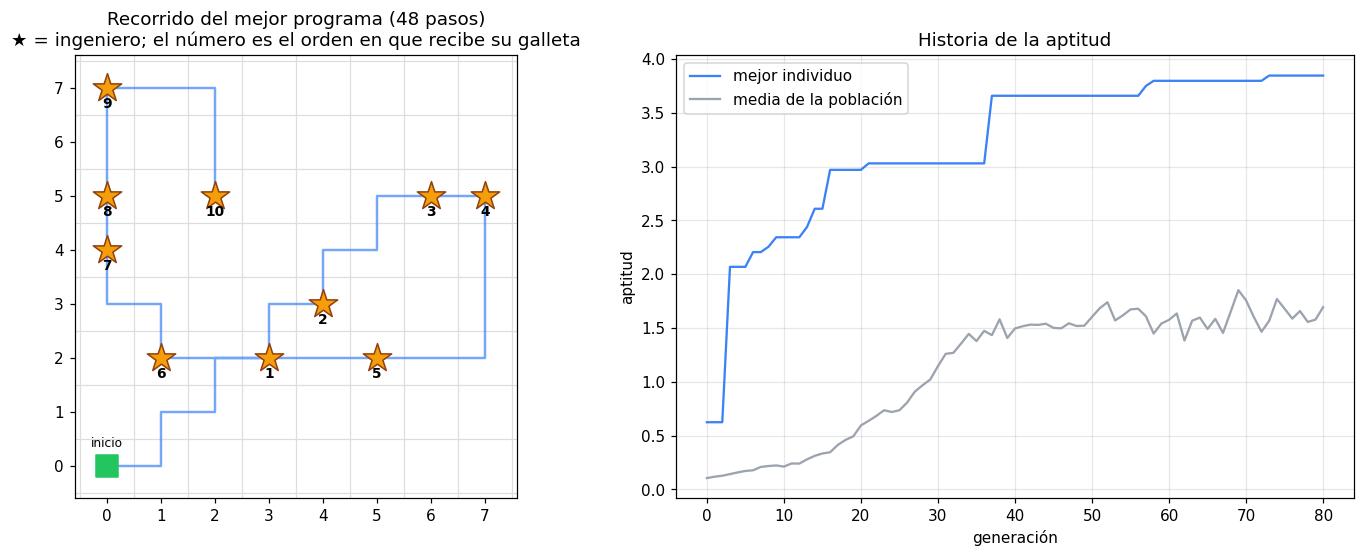

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))

# --- Recorrido del robot
a = ax[0]
for i in range(N + 1):
    a.axhline(i - 0.5, color="#ddd", lw=0.8); a.axvline(i - 0.5, color="#ddd", lw=0.8)
ruta = sim.ruta
a.plot([p[0] for p in ruta], [p[1] for p in ruta], "-", color="#3b82f6", lw=1.6, alpha=0.7, zorder=2)
orden, vistos = [], set()
for p in ruta:
    if p in ingenieros and p not in vistos: vistos.add(p); orden.append(p)
for k, (x, y) in enumerate(orden, 1):
    a.scatter(x, y, marker="*", s=380, color="#f59e0b", edgecolor="#92400e", zorder=3)
    a.text(x, y - 0.38, str(k), ha="center", fontsize=9, fontweight="bold")
for (x, y) in ingenieros - vistos:
    a.scatter(x, y, marker="*", s=380, color="#fca5a5", edgecolor="#b91c1c", zorder=3)
a.scatter(0, 0, marker="s", s=200, color="#22c55e", zorder=4); a.text(0, 0.35, "inicio", ha="center", fontsize=8)
a.set_xlim(-0.6, N - 0.4); a.set_ylim(-0.6, N - 0.4); a.set_aspect("equal")
a.set_title(f"Recorrido del mejor programa ({sim.pasos} pasos)\n★ = ingeniero; el número es el orden en que recibe su galleta")

# --- Evolución de la aptitud
b = ax[1]
b.plot(hist_robot["mejor"], label="mejor individuo", color="#3b82f6")
b.plot(hist_robot["media"], label="media de la población", color="#9ca3af")
b.set_xlabel("generación"); b.set_ylabel("aptitud"); b.set_title("Historia de la aptitud"); b.legend(); b.grid(alpha=.3)
plt.tight_layout(); plt.show()


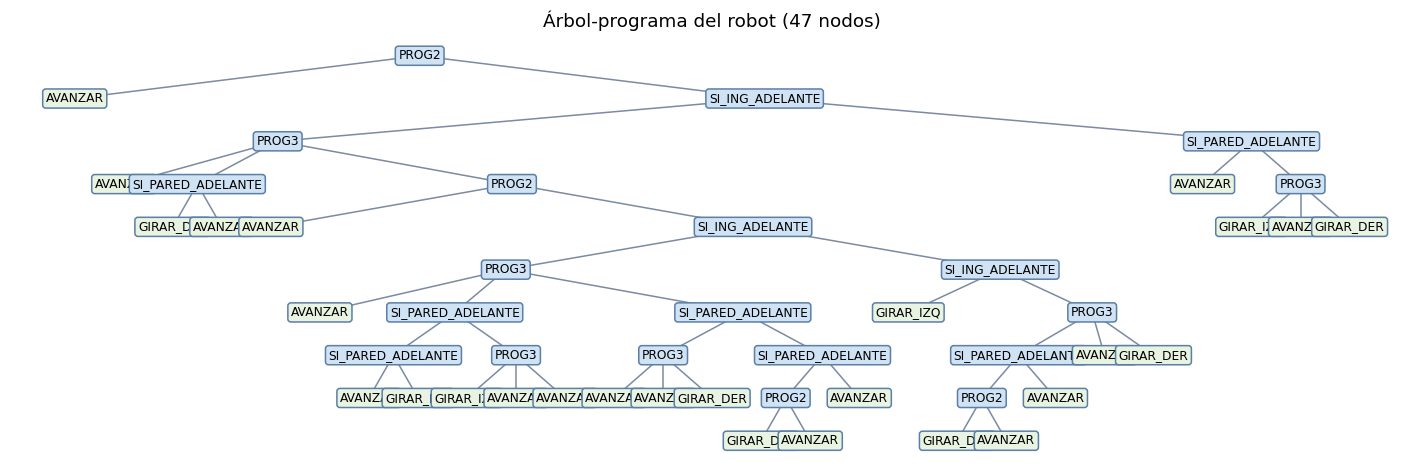

In [9]:
fig, ax = plt.subplots(figsize=(max(8, cuenta_nodos(mejor_robot) * 0.35), 5))
dibujar_arbol(mejor_robot, ax, f"Árbol-programa del robot ({cuenta_nodos(mejor_robot)} nodos)")
plt.show()


### Conclusiones del Ejercicio 2

* La PG **descubrió sin que se le dijera cómo** un recorrido que atiende a los 10 ingenieros dentro del presupuesto de pasos, y la aptitud sube con las generaciones (figura de la derecha).
* El programa resultante es una mezcla de acciones y de condiciones sobre el entorno (`SI_ING_ADELANTE`, `SI_PARED_ADELANTE`), es decir, el **genotipo es el programa mismo** (sin preprocesamiento).
* **Comparación honesta:** el vecino más cercano (referencia) necesita 25 movimientos sin contar giros; el programa evolucionado usa 48 pasos contando giros. No es un recorrido óptimo, pero atiende a los 10 ingenieros dentro del presupuesto y su aptitud seguiría mejorando con más generaciones, mayor población o más premio a la rapidez.
* **Limitación:** el programa se evolucionó para *esta* distribución de ingenieros (igual que la hormiga de Koza sobre un sendero fijo). Para generalizar, bastaría evaluar la aptitud promediando varias distribuciones aleatorias de la sala.

---
# 3. Ejercicio 3 – Detección de fraudes

**Enunciado:** generar aleatoriamente un archivo con *monto en pesos, hora del día, distancia a su residencia, ingreso mensual* y *fraude sí/no*; revisarlo y hacer cambios para que sea más real; encontrar un modelo que determine un posible fraude.

## 3.1 Primer intento: datos aleatorios "ingenuos"
Todo uniforme y la etiqueta lanzada como una moneda.

In [10]:
import pandas as pd

def genera_v1(n=3000, semilla=1):
    """Versión 1 (ingenua): todo uniforme y la etiqueta al azar."""
    r = np.random.default_rng(semilla)
    return pd.DataFrame({
        "monto": r.uniform(1_000, 5_000_000, n).round(-2),
        "hora": r.uniform(0, 24, n).round(2),
        "distancia_km": r.uniform(0, 500, n).round(1),
        "ingreso_mensual": r.uniform(1_000_000, 15_000_000, n).round(-4),
        "fraude": r.integers(0, 2, n)})

def genera_v2(n=6000, tasa_fraude=0.05, semilla=2026):
    """Versión 2 (más realista)."""
    r = np.random.default_rng(semilla)
    es_f = r.random(n) < tasa_fraude
    ingreso = np.clip(r.lognormal(np.log(2_800_000), 0.55, n), 1_000_000, 25_000_000)
    # --- transacciones legítimas
    monto = ingreso * r.lognormal(np.log(0.025), 0.9, n)
    hora = np.where(r.random(n) < 0.95, np.clip(r.normal(15, 4, n), 6, 23.99), r.uniform(0, 6, n))
    dist = np.where(r.random(n) < 0.92, r.exponential(4, n), r.exponential(80, n))
    # --- fraudes
    k = es_f.sum()
    prueba = r.random(k) < 0.20           # 20 % son "pruebas" de monto pequeño
    m_f = ingreso[es_f] * np.where(prueba, r.lognormal(np.log(0.01), 0.7, k), r.lognormal(np.log(0.35), 0.8, k))
    h_f = np.where(r.random(k) < 0.55, r.uniform(0, 6, k), np.clip(r.normal(15, 4, k), 6, 23.99))
    d_f = np.where(r.random(k) < 0.70, r.exponential(250, k), r.exponential(6, k))
    monto[es_f], hora[es_f], dist[es_f] = m_f, h_f, d_f
    return pd.DataFrame({
        "monto": np.maximum(monto, 3_000).round(-2),
        "hora": hora.round(2),
        "distancia_km": dist.round(1),
        "ingreso_mensual": ingreso.round(-4),
        "fraude": es_f.astype(int)})


In [11]:
df1 = genera_v1()
print(df1.head())
print("\nCorrelación de cada variable con 'fraude':")
print(df1.corr()["fraude"].drop("fraude").round(3))

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
acc = cross_val_score(LogisticRegression(max_iter=2000), df1.drop(columns="fraude"), df1.fraude, cv=5).mean()
print(f"\nExactitud de una regresión logística con validación cruzada: {acc:.3f}  (azar = 0.5)")


       monto   hora  distancia_km  ingreso_mensual  fraude
0  2559600.0   2.77         193.3        6520000.0       0
1  4752400.0  21.09         226.1       14810000.0       1
2   721700.0   7.18         405.1        6450000.0       1
3  4743300.0  17.90         100.3       10950000.0       0
4  1559800.0  22.50         286.2        3130000.0       1

Correlación de cada variable con 'fraude':
monto              0.006
hora               0.021
distancia_km       0.014
ingreso_mensual   -0.041
Name: fraude, dtype: float64

Exactitud de una regresión logística con validación cruzada: 0.516  (azar = 0.5)


## 3.2 Revisión: ¿qué está mal y cómo se corrige?

Con las etiquetas al azar **no existe ningún patrón** que aprender (correlaciones ≈ 0 y exactitud ≈ 50 %). Además los datos no se parecen a la realidad. Cambios hechos:

| Problema de la versión 1 | Cambio en la versión 2 |
|---|---|
| El fraude era 50/50 | **Clase desbalanceada:** ≈ 5 % de fraudes (en la realidad es aún menor; se deja 5 % para tener ejemplos suficientes). |
| Ingreso uniforme | **Lognormal** (muchos ingresos medios/bajos, pocos muy altos), entre 1 y 25 millones de pesos. |
| Monto uniforme, independiente del ingreso | El monto legítimo es **una fracción pequeña del ingreso** (lognormal, mediana ≈ 2.5 % del ingreso). |
| Hora uniforme | Las compras legítimas se concentran **de día/tarde** (6 a 24 h), con muy pocas de madrugada. |
| Distancia uniforme | Lo normal es **comprar cerca** de casa (exponencial); algunas compras legítimas ocurren lejos (viajes). |
| El fraude no dejaba huella | Los fraudes tienen **montos altos respecto al ingreso**, tienden a ocurrir de **madrugada** y **lejos de la residencia**. |
| Casos perfectamente separables | Se agrega **ruido realista**: 20 % de los fraudes son "pruebas" de monto pequeño, 45 % ocurren en horas normales y 30 % cerca de casa. Por eso el problema **no** es trivial. |

In [12]:
df = genera_v2()
df.to_csv("transacciones_fraude.csv", index=False)
print("Archivo guardado: transacciones_fraude.csv")
print(df.head(8).to_string())
print(f"\nTransacciones: {len(df)} | fraudes: {df.fraude.sum()} ({df.fraude.mean():.1%})")
print("\nMedianas por clase:")
print(df.groupby("fraude").median().round(1).to_string())


Archivo guardado: transacciones_fraude.csv
      monto   hora  distancia_km  ingreso_mensual  fraude
0   97500.0  13.21           0.8        4860000.0       0
1  247000.0  23.99           1.9        3730000.0       0
2  165900.0  17.22           9.2        5530000.0       0
3   73300.0  10.24           0.8        1660000.0       0
4    7500.0   8.99           0.2        1000000.0       0
5   38000.0  17.83           2.1        1040000.0       0
6  247300.0   7.61          13.5        3270000.0       0
7   87700.0  15.65           1.3        1300000.0       0

Transacciones: 6000 | fraudes: 267 (4.5%)

Medianas por clase:
           monto  hora  distancia_km  ingreso_mensual
fraude                                               
0        70700.0  14.8           3.0        2810000.0
1       625800.0   5.5          57.5        2770000.0


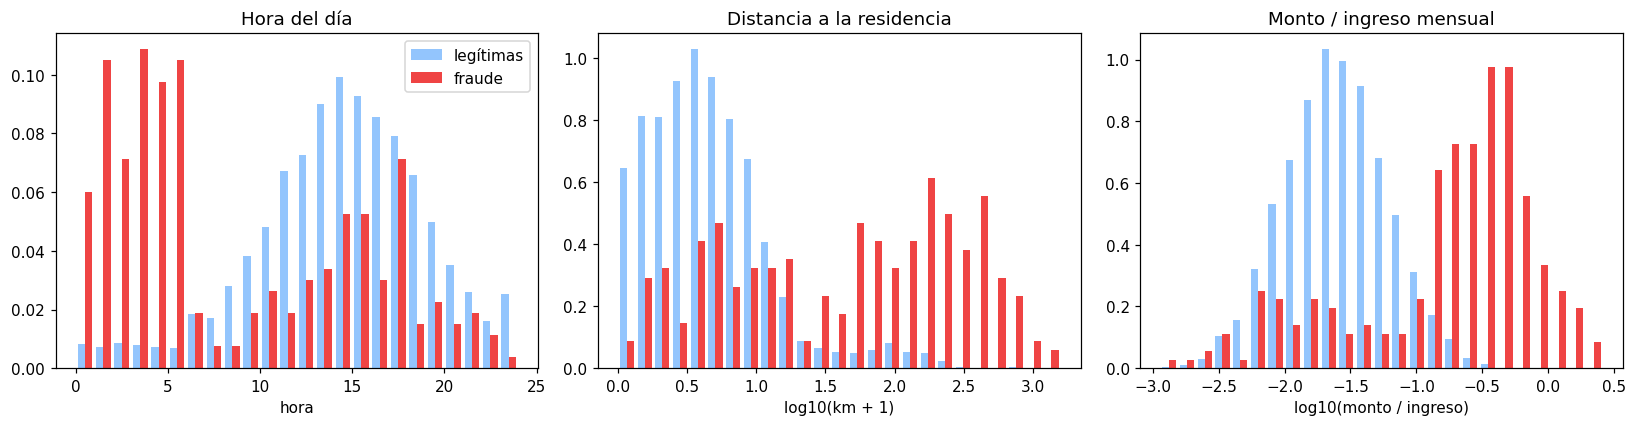

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ok, fr_ = df[df.fraude == 0], df[df.fraude == 1]
ax[0].hist([ok.hora, fr_.hora], bins=24, density=True, label=["legítimas", "fraude"], color=["#93c5fd", "#ef4444"])
ax[0].set_title("Hora del día"); ax[0].set_xlabel("hora"); ax[0].legend()
ax[1].hist([np.log10(ok.distancia_km + 1), np.log10(fr_.distancia_km + 1)], bins=25, density=True, color=["#93c5fd", "#ef4444"])
ax[1].set_title("Distancia a la residencia"); ax[1].set_xlabel("log10(km + 1)")
ax[2].hist([np.log10(ok.monto / ok.ingreso_mensual), np.log10(fr_.monto / fr_.ingreso_mensual)], bins=25, density=True, color=["#93c5fd", "#ef4444"])
ax[2].set_title("Monto / ingreso mensual"); ax[2].set_xlabel("log10(monto / ingreso)")
plt.tight_layout(); plt.show()


## 3.3 Modelo por Programación Genética

### Los 6 pasos preparatorios
1. **Problema.** Clasificación binaria: encontrar una expresión matemática $y = g(\text{monto}, \text{hora}, \text{distancia}, \text{ingreso})$ tal que **la transacción es fraude si $y > 0$** (es lo que el documento llama regresión/clasificación simbólica; MEPX lo llama *umbral automático*).
2. **Terminales T:** `monto` (millones de pesos), `hora` (0–24), `distancia` (cientos de km), `ingreso` (millones de pesos) y **constantes** aleatorias en [−5, 25]. Las unidades se escalan solo para que las constantes aleatorias tengan órdenes de magnitud comparables.
3. **Funciones F:** `+`, `-`, `*`, `/` (protegida: si el divisor es ≈ 0 devuelve 1), `MIN`, `MAX`, `ABS` y `SI(c, a, b)` (si `c > 0` entonces `a`, si no `b`). Todas operan sobre reales y devuelven reales → **clausura**.
4. **Aptitud.** Se usa la forma del documento, $f_{apt} = \dfrac{1}{0.1 + error}$, con
   $error = FNR + 2\cdot FPR + 0.0002\cdot\text{nodos}$,
   donde FNR = fracción de fraudes no detectados y FPR = fracción de transacciones legítimas bloqueadas por error. Como los fraudes son pocos, la *exactitud* sería engañosa (decir "nunca hay fraude" daría 95 %), por eso se miden **las tasas por clase**; el peso 2 en FPR refleja que bloquear clientes legítimos también cuesta; el último término penaliza árboles enormes.
5. **Parámetros:** población = 300, generaciones = 120, prob. de cruce = 0.7, prob. de mutación = 0.02 por nodo, torneo de 3, elitismo, profundidad máxima = 7. Se hacen **5 corridas**.
6. **Resultado y terminación:** el individuo de mayor aptitud *en el conjunto de entrenamiento*; la corrida termina a la generación 120.

Los datos se dividen en **70 % entrenamiento / 30 % prueba** (estratificado). El conjunto de prueba **no se usa en ningún momento de la evolución**.

In [14]:
# ---- primitivas
def pdiv(a, b):
    with np.errstate(all="ignore"):
        return np.where(np.abs(b) > 1e-6, a / np.where(np.abs(b) > 1e-6, b, 1.0), 1.0)
OPS = {
    "+": (2, lambda a, b: a + b), "-": (2, lambda a, b: a - b), "*": (2, lambda a, b: a * b),
    "/": (2, pdiv), "MIN": (2, np.minimum), "MAX": (2, np.maximum), "ABS": (1, np.abs),
    "SI": (3, lambda c, a, b: np.where(c > 0, a, b)),
}
def evalua_arbol(t, X):
    v = t.valor
    if not t.hijos:
        return np.full(len(next(iter(X.values()))), v) if isinstance(v, float) else X[v]
    args = [evalua_arbol(h, X) for h in t.hijos]
    with np.errstate(all="ignore"):
        r = OPS[v][1](*args)
    return np.clip(np.nan_to_num(r, nan=0.0, posinf=1e9, neginf=-1e9), -1e9, 1e9)

P_FRAUDE = Primitivas(funciones={k: v[0] for k, v in OPS.items()},
                      terminales=["monto", "hora", "distancia", "ingreso"],
                      constantes=lambda rng: round(rng.uniform(-5, 25), 2), p_const=0.25)

def prepara_X(df):
    return {"monto": (df.monto/1e6).values, "hora": df.hora.values,
            "distancia": (df.distancia_km/100).values, "ingreso": (df.ingreso_mensual/1e6).values}

def hacer_evaluador(X, y, lam=0.0002):
    pos, neg = (y == 1), (y == 0)
    def evaluar(t):
        pred = evalua_arbol(t, X) > 0
        fnr = np.mean(~pred[pos]); fpr = np.mean(pred[neg])
        error = fnr + fpr + lam * cuenta_nodos(t)
        return 1.0 / (0.1 + error)
    return evaluar


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, balanced_accuracy_score, precision_score, recall_score

df = pd.read_csv("transacciones_fraude.csv")
tr, te = train_test_split(df, test_size=0.3, stratify=df.fraude, random_state=0)
Xtr, Xte = prepara_X(tr), prepara_X(te)
ytr, yte = tr.fraude.values, te.fraude.values
pos, neg = (ytr == 1), (ytr == 0)

def evaluar_fraude(t, w_fpr=2.0, lam=0.0002):
    pred = evalua_arbol(t, Xtr) > 0
    error = np.mean(~pred[pos]) + w_fpr * np.mean(pred[neg]) + lam * cuenta_nodos(t)
    return 1.0 / (0.1 + error)

corridas = []
for semilla in range(5):
    mejor, apt, hist = evolucionar(P_FRAUDE, evaluar_fraude, tam_pob=300, generaciones=120,
                                   p_cruce=0.7, p_mut=0.02, prof_max=7, prof_ini=4,
                                   k_torneo=3, semilla=semilla, verbose=0)
    corridas.append((apt, semilla, mejor, hist))
    print(f"corrida {semilla}: aptitud(train) = {apt:.3f} | nodos = {cuenta_nodos(mejor)}")

apt_f, semilla_f, mejor_f, hist_f = max(corridas, key=lambda c: c[0])
print(f"\nSe elige la corrida {semilla_f} (mayor aptitud en entrenamiento)")
print("\nModelo evolucionado (fraude si > 0):")
print(a_texto(mejor_f))


corrida 0: aptitud(train) = 2.968 | nodos = 20
corrida 1: aptitud(train) = 2.836 | nodos = 25
corrida 2: aptitud(train) = 3.039 | nodos = 23
corrida 3: aptitud(train) = 3.310 | nodos = 52
corrida 4: aptitud(train) = 3.144 | nodos = 27

Se elige la corrida 3 (mayor aptitud en entrenamiento)

Modelo evolucionado (fraude si > 0):
(((MAX(((21.4 / ingreso) * (3.85 * monto)), MAX(4.31, monto)) - hora) + (MAX((distancia * distancia), SI(hora, distancia, monto)) - 5.9)) + (MAX((14.4 * distancia), ABS(distancia)) + MIN(((22 / 20.9) * ((24.1 * monto) * ABS(distancia))), (((22.3 / ingreso) * (3.93 * monto)) - hora))))


In [16]:
def metricas(y, p):
    return {"precisión": precision_score(y, p, zero_division=0), "recall (fraudes detectados)": recall_score(y, p),
            "F1": f1_score(y, p), "exactitud balanceada": balanced_accuracy_score(y, p)}

from sklearn.tree import DecisionTreeClassifier
cols = ["monto", "hora", "distancia_km", "ingreso_mensual"]
logreg = LogisticRegression(max_iter=5000, class_weight="balanced").fit(tr[cols], ytr)
arbol_sk = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=0).fit(tr[cols], ytr)

p_gp = evalua_arbol(mejor_f, Xte) > 0
tabla = pd.DataFrame({
    "Programación Genética": metricas(yte, p_gp),
    "Regresión logística": metricas(yte, logreg.predict(te[cols])),
    "Árbol de decisión (prof. 4)": metricas(yte, arbol_sk.predict(te[cols])),
}).T.round(3)
print("RESULTADOS EN EL CONJUNTO DE PRUEBA (datos nunca vistos)\n")
print(tabla.to_string())

cm = confusion_matrix(yte, p_gp)
print("\nMatriz de confusión de la PG (prueba):")
print(pd.DataFrame(cm, index=["real: legítima", "real: fraude"], columns=["pred: legítima", "pred: fraude"]).to_string())


RESULTADOS EN EL CONJUNTO DE PRUEBA (datos nunca vistos)

                             precisión  recall (fraudes detectados)     F1  exactitud balanceada
Programación Genética            0.627                        0.800  0.703                 0.889
Regresión logística              0.372                        0.838  0.515                 0.886
Árbol de decisión (prof. 4)      0.406                        0.862  0.552                 0.902

Matriz de confusión de la PG (prueba):
                pred: legítima  pred: fraude
real: legítima            1682            38
real: fraude                16            64


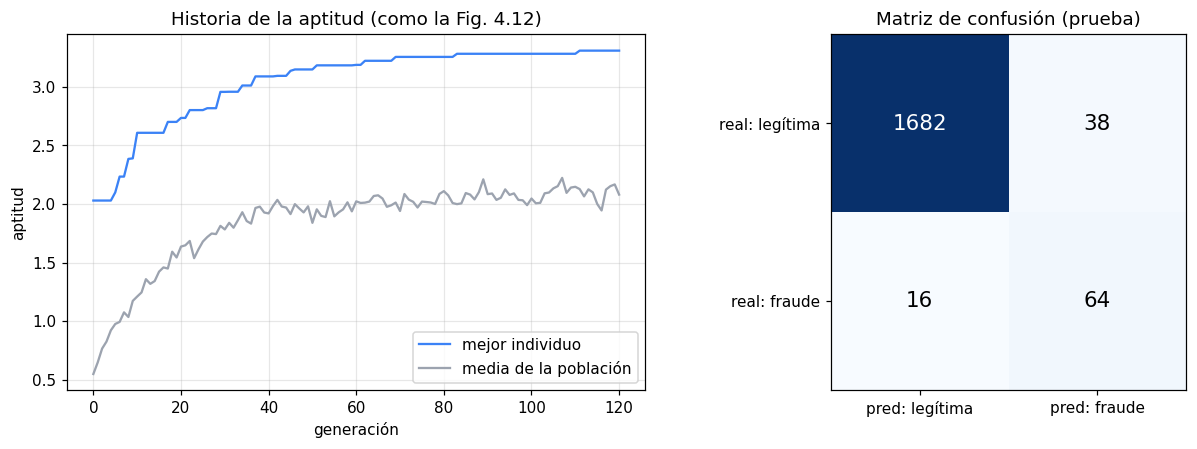

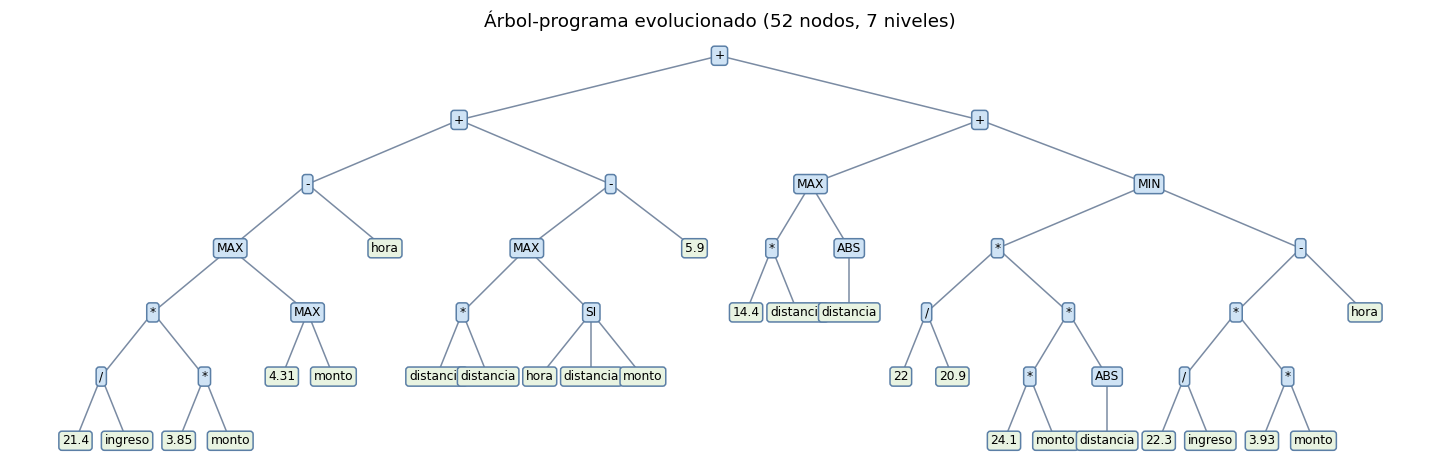

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(hist_f["mejor"], label="mejor individuo", color="#3b82f6")
ax[0].plot(hist_f["media"], label="media de la población", color="#9ca3af")
ax[0].set_xlabel("generación"); ax[0].set_ylabel("aptitud"); ax[0].set_title("Historia de la aptitud (como la Fig. 4.12)")
ax[0].legend(); ax[0].grid(alpha=.3)
im = ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max()/2 else "black")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["pred: legítima", "pred: fraude"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["real: legítima", "real: fraude"]); ax[1].set_title("Matriz de confusión (prueba)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(max(9, cuenta_nodos(mejor_f) * 0.32), 5))
dibujar_arbol(mejor_f, ax, f"Árbol-programa evolucionado ({cuenta_nodos(mejor_f)} nodos, {profundidad(mejor_f)} niveles)")
plt.show()


In [18]:
# ¿Qué variables usó el modelo y cómo se comporta? (interpretación)
usos = pd.Series([n.valor for n in preorden(mejor_f) if isinstance(n.valor, str) and n.valor in P_FRAUDE.terminales]).value_counts()
print("Veces que cada variable aparece en el árbol:\n", usos.to_string())

te2 = te.copy(); te2["alerta_PG"] = p_gp
te2["madrugada"] = te2.hora < 6
te2["lejos(>50km)"] = te2.distancia_km > 50
te2["monto>20%ingreso"] = te2.monto > 0.2 * te2.ingreso_mensual
print("\nPorcentaje de transacciones marcadas como fraude según el tipo de transacción (prueba):")
for c in ["madrugada", "lejos(>50km)", "monto>20%ingreso"]:
    print(f"  {c:18s}  sí: {te2[te2[c]].alerta_PG.mean():6.1%}   no: {te2[~te2[c]].alerta_PG.mean():6.1%}")


Veces que cada variable aparece en el árbol:
 distancia    6
monto        5
hora         3
ingreso      2

Porcentaje de transacciones marcadas como fraude según el tipo de transacción (prueba):
  madrugada           sí:  40.5%   no:   3.4%
  lejos(>50km)        sí:  52.3%   no:   2.7%
  monto>20%ingreso    sí:  85.1%   no:   2.3%


### Conclusiones del Ejercicio 3

* Con **datos aleatorios ingenuos** ningún modelo puede aprender nada (≈ 50 %), lo que muestra por qué hubo que *revisar y mejorar* el archivo: se agregaron relaciones plausibles entre monto/ingreso, hora y distancia, desbalance de clases y ruido.
* La PG **encontró por sí sola** una expresión que combina las variables y que **no se le dio de antemano** (no se le indicó la forma de la función). Aunque algunos términos son "ruido" evolutivo (*intrones*), las variables que más pesan son las que se usaron para generar los fraudes: el monto relativo, la hora y la distancia.
* En datos de prueba, la PG logra resultados **comparables o mejores en F1** que la regresión logística y el árbol de decisión de referencia, con la ventaja de que el resultado es una **expresión explícita** (un programa).
* **Cuidados:** (i) los fraudes son pocos, así que se mide por clase y no por exactitud; (ii) los datos son sintéticos, por lo que estos números **no** predicen el desempeño real; (iii) se limitó la profundidad de los árboles para evitar el crecimiento descontrolado.